In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
df = sns.load_dataset("titanic")

df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
print("Rows and columns:", df.shape)

Rows and columns: (891, 15)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


In [5]:
print(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [6]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.describe(include="object")

C:\Users\X280\AppData\Local\Temp\ipykernel_18248\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,sex,embarked,who,embark_town,alive
count,891,889,891,889,891
unique,2,3,3,3,2
top,male,S,man,Southampton,no
freq,577,644,537,644,549


survived
0    549
1    342
Name: count, dtype: int64


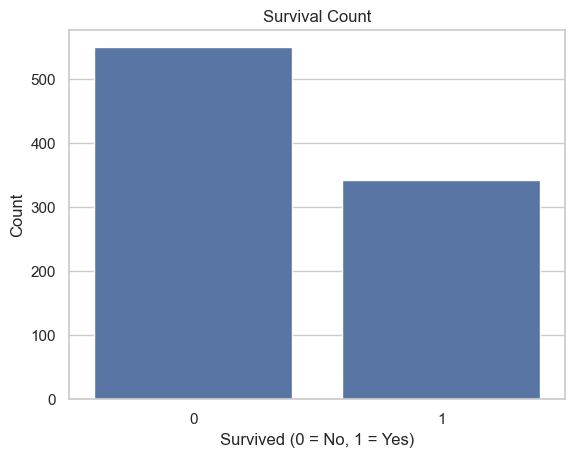

In [8]:
print(df["survived"].value_counts())

sns.countplot(data=df, x="survived")
plt.title("Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

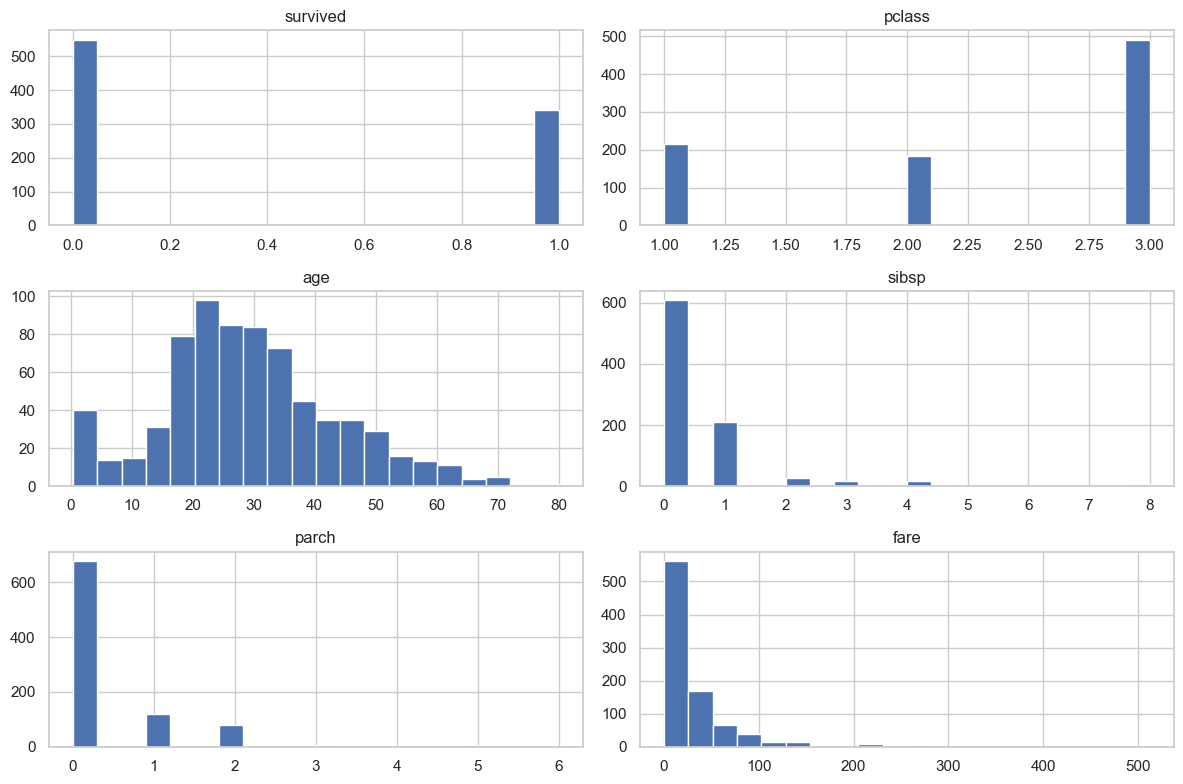

In [9]:
numeric_cols = df.select_dtypes(include="number").columns

df[numeric_cols].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

pclass   -0.338481
fare      0.257307
parch     0.081629
age      -0.077221
sibsp    -0.035322
Name: survived, dtype: float64


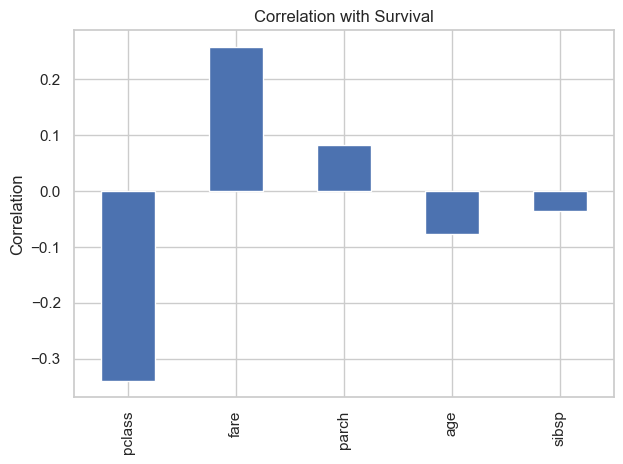

In [10]:
correlation = df[numeric_cols].corr()

target_corr = correlation["survived"].drop("survived")
target_corr = target_corr.sort_values(key=abs, ascending=False)

print(target_corr)

target_corr.plot(kind="bar")
plt.title("Correlation with Survival")
plt.ylabel("Correlation")
plt.tight_layout()
plt.show()

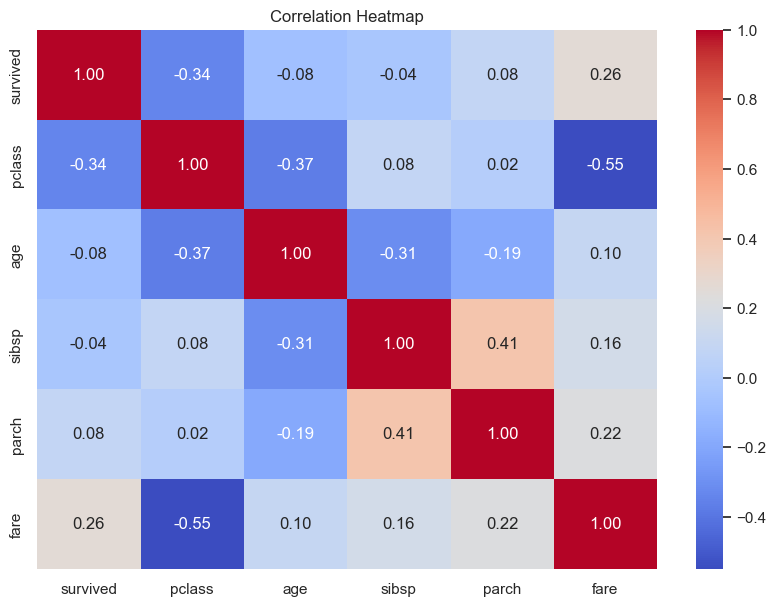

In [11]:
plt.figure(figsize=(10, 7))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

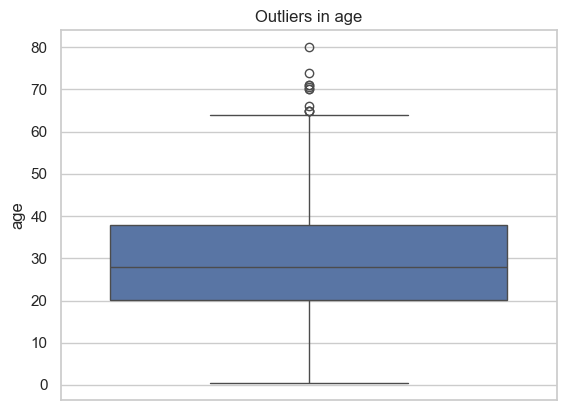

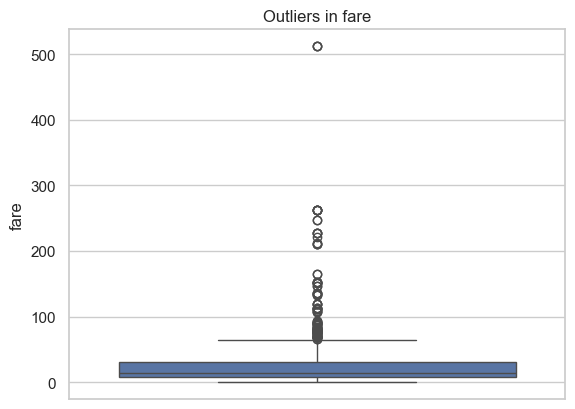

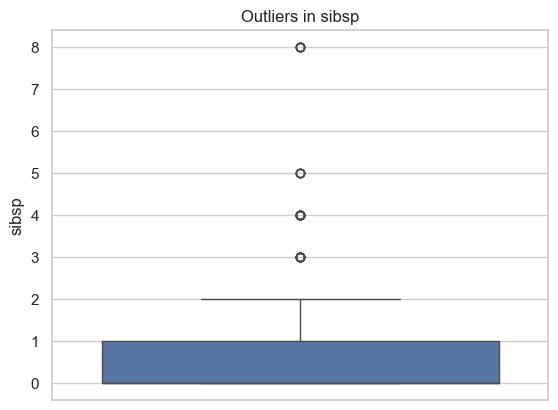

In [12]:
outlier_cols = ["age", "fare", "sibsp"]

for col in outlier_cols:
    sns.boxplot(data=df, y=col)
    plt.title("Outliers in " + col)
    plt.show()

In [13]:
for col in outlier_cols:
    values = df[col].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = values[(values < lower) | (values > upper)]

    print(col, "outliers:", len(outliers))

age outliers: 11
fare outliers: 116
sibsp outliers: 46


survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


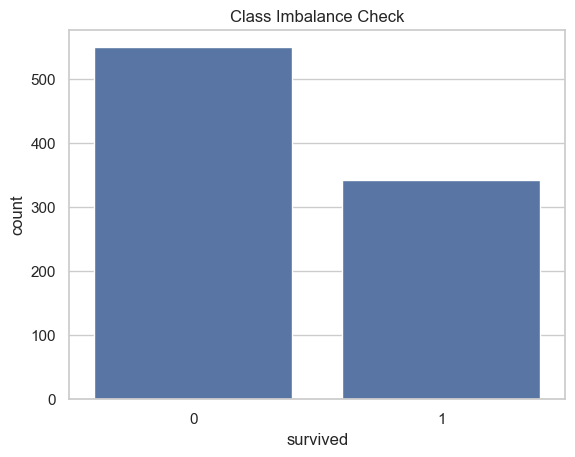

In [14]:
print(df["survived"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="survived")
plt.title("Class Imbalance Check")
plt.show()

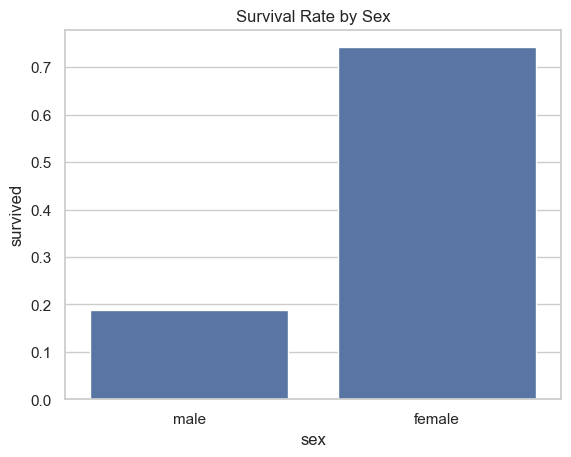

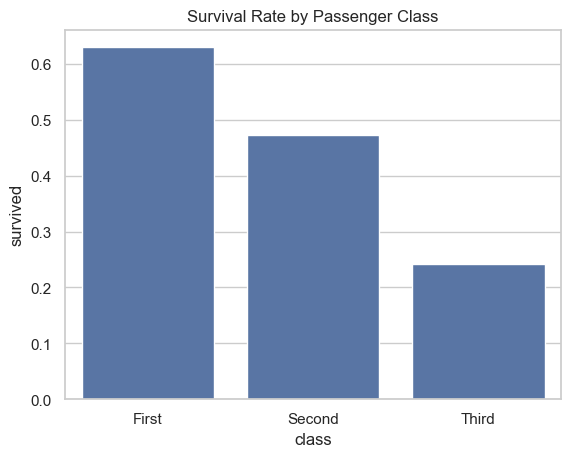

In [15]:
sns.barplot(data=df, x="sex", y="survived", errorbar=None)
plt.title("Survival Rate by Sex")
plt.show()

sns.barplot(data=df, x="class", y="survived", errorbar=None)
plt.title("Survival Rate by Passenger Class")
plt.show()

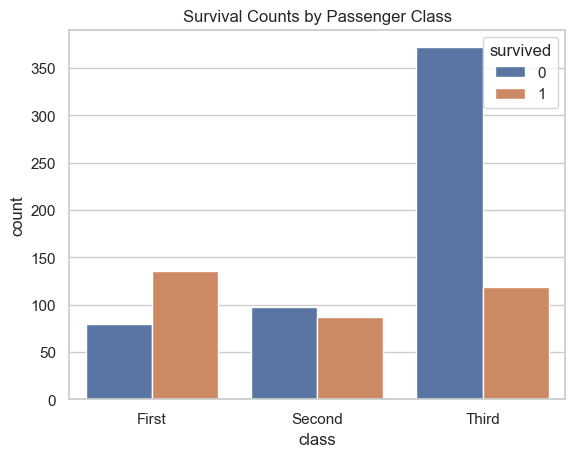

In [16]:
sns.countplot(data=df, x="class", hue="survived")
plt.title("Survival Counts by Passenger Class")
plt.show()

In [17]:
survival = df["survived"].mean() * 100
missing = df.isnull().sum().sum()

print("EDA SUMMARY")
print("Dataset shape:", df.shape)
print("Survival percentage:", round(survival, 2), "%")
print("Missing values:", missing)
print("Check the correlation plot for important numerical features.")
print("Check boxplots for possible outliers.")
print("Check countplots for target class imbalance.")
print("Compare survival rates by sex and passenger class.")

EDA SUMMARY
Dataset shape: (891, 15)
Survival percentage: 38.38 %
Missing values: 869
Check the correlation plot for important numerical features.
Check boxplots for possible outliers.
Check countplots for target class imbalance.
Compare survival rates by sex and passenger class.
